# Voltage optimization benchmark

We measure the optimization time, required for minimum positions, mode angle rotations, and secular frequencies, depending on the number of individual wells in the trap from the article 
[https://doi.org/10.48550/arXiv.2211.07121]. Each well adds additional 5 electrodes - 4 DC and 1 RF, as well as 4 more polygon points to the general RF electrode. This way, the geometry bounds the effect of the "good starting point" on the optimization routine.

- **Positions:** move every selected well to `minimum + 1` µm.
- **Frequencies:** for **each selected axis**, target `1.10 ×` -- zero-DC frequency across selected wells. Test all chosen combinations of mode indices `[0, 1, 2]`.
- **Modes:** target the signed angle `alpha = 0.1 rad`. This one necessitates non zero starting voltage. The initial guess for voltage is kept the same for all modes optimizations.
- **Micromotion:** test weights `0` and `0.1` for frequency and mode tasks.

 We repeat these benchmarks for 3 traps with different electrode selectivity, depending on the ion-trap distance: 20, 50, 80 um. The resulting simulation times are analyzed for the number of additional simulation points and electrodes for 3 trap geometries to establish a case-specific trend on the simulation time scaling.

In [ ]:
from pathlib import Path
import datetime as dt
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.constants as ct
import sion as sn
from sion.electrode import System, PolygonPixelElectrode

L = 1e-6
M = 40 * ct.atomic_mass      # Ca-40 ion mass [kg]
Z = ct.elementary_charge     # single-ion charge [C]

# ---- Main benchmark settings ----
RUN_BENCHMARK = False
LOAD_CSV = None              # path to an earlier *_runs.csv for plotting only
SCOPE = 'full'               # 'single', 'test', 'pilot', 'full'
REPEATS = 1                 # >=3 for publication timing
EDGE_CUTOFF = 2
TASKS = ('position', 'frequency', 'mode')

# Frequency: all single-, double-, and triple-axis choices.
# Use ([1],) to reproduce the previous frequency benchmark quickly.
FREQUENCY_AXES = ([1], [0], [2], [0, 1], [0, 2], [1, 2], [0, 1, 2])
MICRO_VALUES = (0, 0.1)      # applied to frequency and mode optimization
FREQUENCY_TARGET_FACTOR = 1.10  # 10% higher than zero-DC reference

MODE_SEED_V = {20: 0.3, 50: 1.0, 80: 2.0}  # [+V, 0, -V] per well
VOLTAGE_BOUNDS = (-30, 30)  # V
ALPHA = 0.1                 # rad

# Final objective-mismatch tolerances. Stability and site displacement are separate.
POSITION_RMS_TOL_UM = 0.1
POSITION_MAX_TOL_UM = 0.2
FREQUENCY_RMS_REL_TOL = 0.01
FREQUENCY_MAX_REL_TOL = 0.02
MODE_RMS_TOL_RAD = 0.02
MODE_MAX_TOL_RAD = 0.03

OUTPUT_DIR = Path.cwd() / 'supplementary' / 'voltage_optimization'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


## 1. Electrode geometry

The function, defining the trap from the [1] is written below. It plots the resulting trap on two plots: electrodes, with each electrodes of the different color, and RF-amplitude, demonstrated on 'bwr' colormap. 

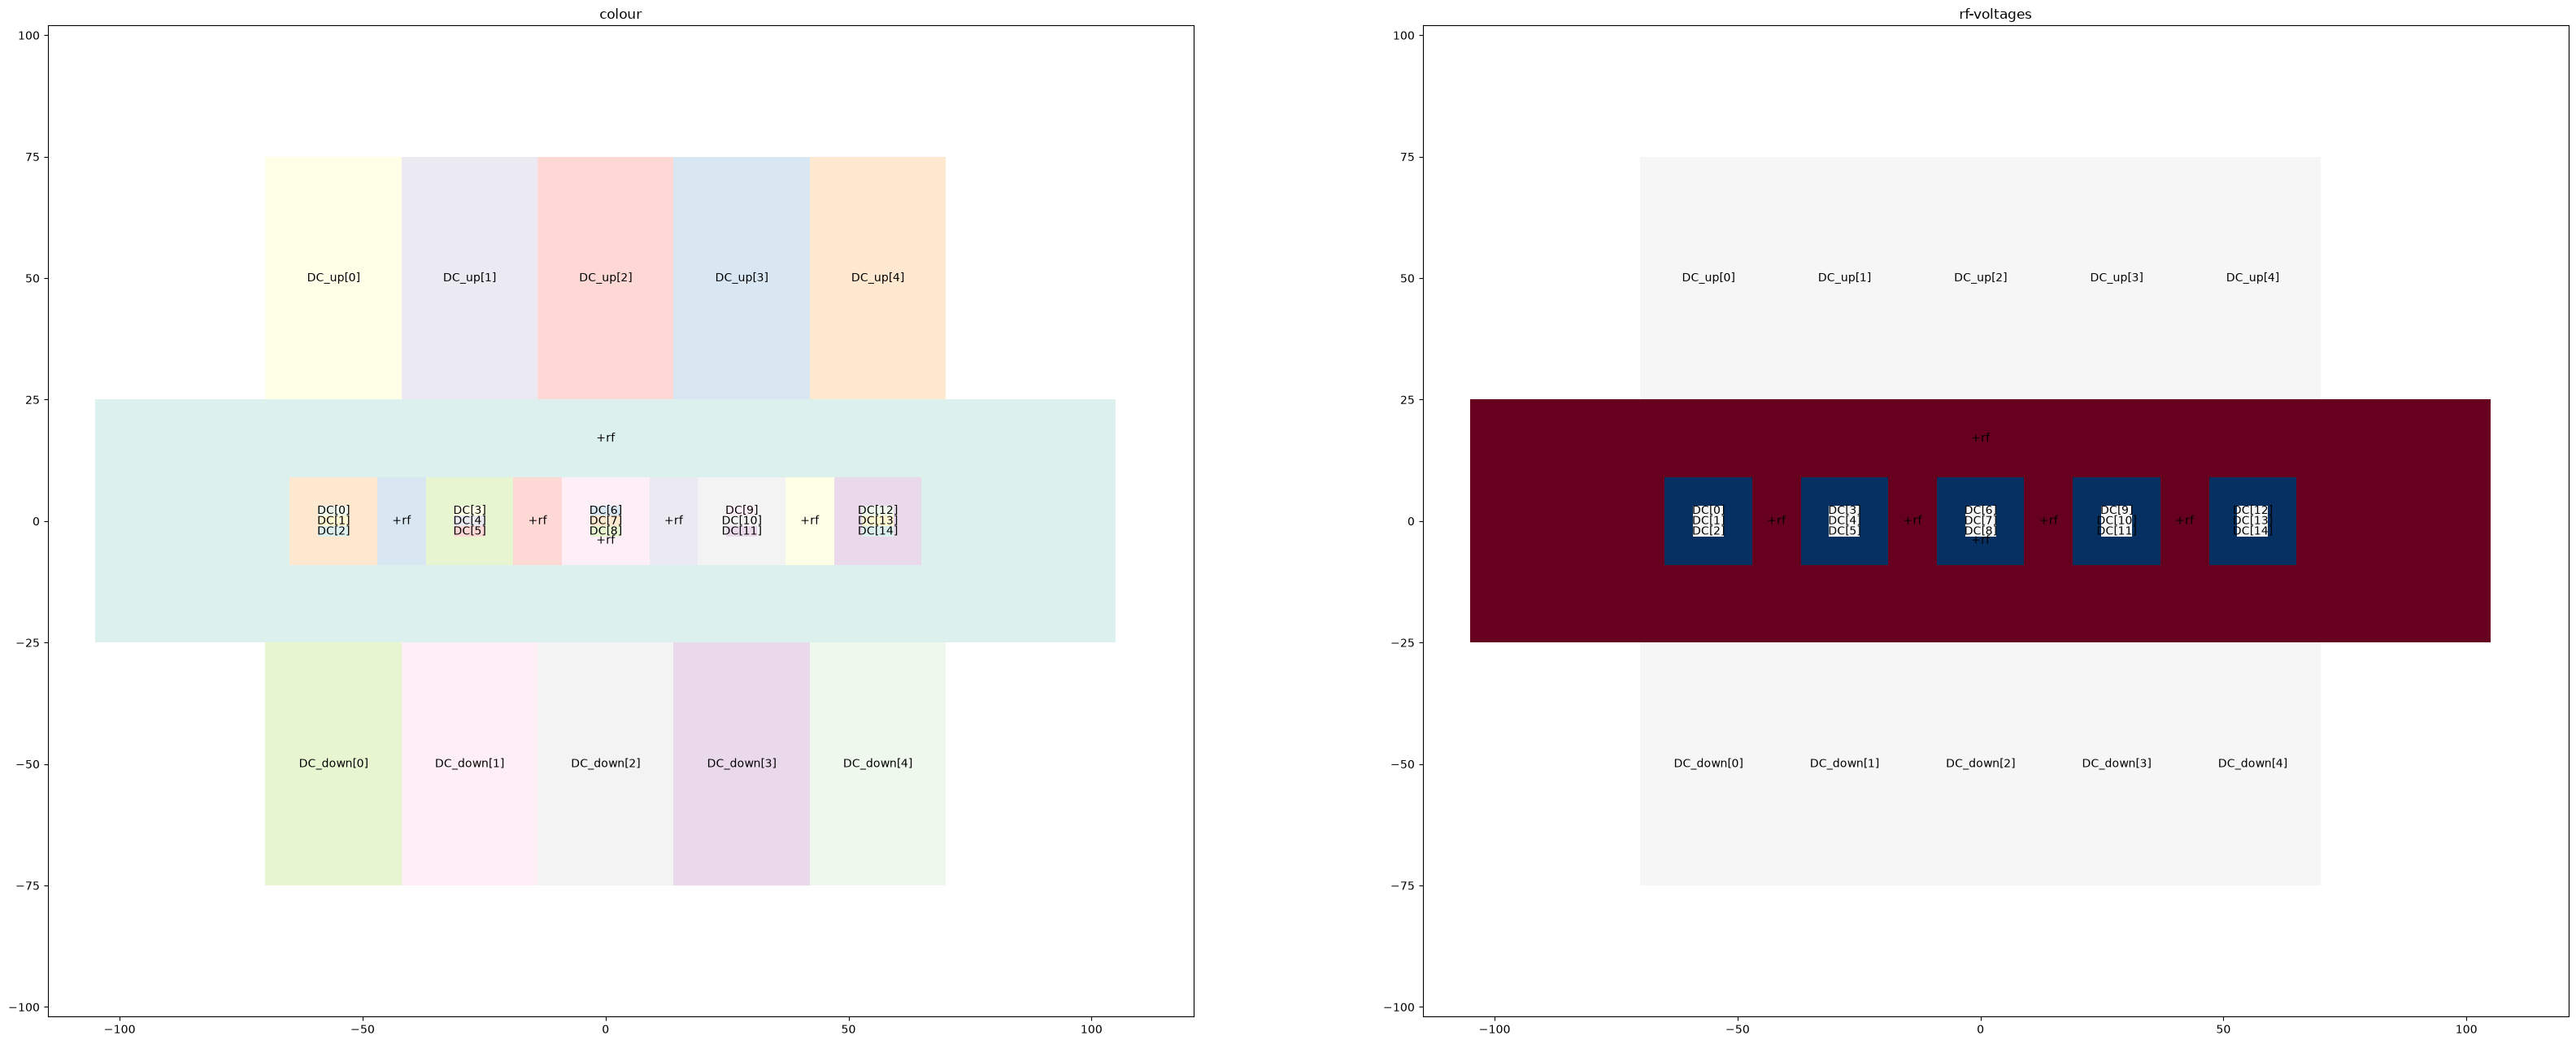

In [8]:
def array_trap(Urf, width, sq, n, inner_square, dc, side_dc, a, b, g, L, cheight=0, cmax=0, need_plot=True):
    """
    Generates the trap from the article: https://doi.org/10.48550/arXiv.2211.07121
   
    
    Urf = [U+, U-]  rf amplitude of +rf and -rf squares
    width: float, width of +rf electrode borders
    sq: float, side of the inner square of rf+
    n: int, number of individual traps
    inner_square = [R_ex, r_in] external and inner sides of -rf square
    dc: float, side pf central DC square
    side_dc: height of side dc electrodes
    a: float, anisotropy: parameter, by which we multiply far left and
    far right width of +rf
    b: parameter, by which we multiply outer side width of rf+ electrode
    g: parameter, by which we multiply inner width of rf+ and rf-
    L: geomtry scale of the trap
    return: coordinates: list of coordinates to apply to polygon_trap()
    as [RF_coordinates, DC_coordinates]
            s: System object for electrode
    """
    dis = ((sq+width)*n+width)/2-(width+sq/2)
    rf_ex1 = [[-width*a-sq/2-dis, g*sq/2], [(n-0.5)*sq+(n-1+a)*width-dis, g*sq/2], [(
        n-0.5)*sq+(n-1+a)*width-dis, g*sq/2+b*width], [-a*width-sq/2-dis, g*sq/2+b*width]]
    rf_ex2 = [[-a*width-sq/2-dis, g*sq/2], [-a*width-sq/2-dis, -b*width-g*sq/2],
              [(n-0.5)*sq+(n-1+a)*width-dis, -g*sq/2-b*width], [(n-0.5)*sq+(n-1+a)*width-dis, g*sq/2], 
              [(n-0.5)*sq+n*width - 1*width-dis, g*sq/2], [(n-0.5)*sq + n*width - (1)*width - dis, -g*sq/2],
              [(n - 0.5)*sq + n*width - (n-1 + 1)*width - (n-1)*sq-sq-dis, -g*sq/2], [(n - 0.5)*sq + n*width - (n-1 + 1)*width - (n-1)*sq-sq-dis, g*sq/2] ]
    RF_coordinates = [np.array(rf_ex1)*L, np.array(rf_ex2)*L]
    
    rf_ex3 = []
    for i in range(n-1):
        rf_ex33 = [[(n - 0.5) * sq + n * width - (i + 2)
                      * width - (i+1) * sq-dis, g*sq / 2],
                      [(n - 0.5) * sq + n * width - (i + 2)
                      * width - (i+1) * sq-dis, -g*sq / 2],
                      [(n - 0.5) * sq + n * width - (i + 1)
                      * width - (i+1) * sq-dis, -g*sq / 2],[(n-0.5)*sq+n*width - (i+1)*width-(i+1)*sq-dis, g*sq/2]]
        rf_ex3.append([rf_ex33])
        RF_coordinates.append(np.array(rf_ex33)*L)

    electrodes = [
        ("+rf", [rf_ex1,
                 rf_ex2])]
    for i in range(n-1):
        # st = "-rf[" + str(i) +"]"
        electrodes.append(["+rf", rf_ex3[i]])

    R = inner_square[0]
    r = inner_square[1]

    rf_in = []
    for i in range(n):
        c = i*(sq+width)-dis
        top = np.array([[c - R/2, g*r/2], [c+R/2, g*r/2],
                       [c+R/2, g*R/2], [c-R/2, g*R/2]])
        bottom = np.array([[c-R/2, g*r/2], [c-R/2, -g*R/2], [c+R/2, -g*R/2], [c+R/2, g*r/2],
                          [c+r/2, g*r/2], [c+r/2, -g*r/2], [c-r/2, -g*r/2], [c-r/2, g*r/2]])
        rf_in.append([top, bottom])
        RF_coordinates.append(np.array(top)*L)
        RF_coordinates.append(np.array(bottom)*L)

    for i in range(n):
        # st = "-rf[" + str(i) +"]"
        electrodes.append(["", rf_in[i]])

    DC_coordinates = []

    dc_el = []
    for i in range(n):
        c = i * (sq + width)-dis
        elec = np.array([[c-dc/2, g*dc/2], [c-dc/2, g*dc/6],
                        [c+dc/2, g*dc/6], [c+dc/2, g*dc/2]])
        dc_el.append(np.array([elec]))
        DC_coordinates.append(np.array(elec)*L)
        elec = np.array([[c-dc/2, g*dc/6], [c-dc/2, -g*dc/6],
                                [c+dc/2, -g*dc/6], [c+dc/2, g*dc/6]])
        dc_el.append(np.array([elec]))
        DC_coordinates.append(np.array(elec)*L)
        elec = np.array([[c-dc/2, -g*dc/6], [c-dc/2, -g*dc/2],
                                [c+dc/2, -g*dc/2], [c+dc/2, -g*dc/6]])
        dc_el.append(np.array([elec]))
        DC_coordinates.append(np.array(elec)*L)

    dc_up = []
    dc_down = []
    for i in range(n):
        c = i * (sq + width) - dis
        elec_up = np.array([[c-dc/2-(R-r)/2-width/2, g*dc/2+g*(R-r)/2+b*width+side_dc], [c-dc/2-(R-r)/2-width/2, g*dc/2+g*(R-r)/2+b*width], [
                           c+dc/2+(R-r)/2+width/2, g*dc/2+g*(R-r)/2+b*width], [c+dc/2+(R-r)/2+width/2, g*dc/2+g*(R-r)/2+b*width+side_dc]])
        elec_down = np.array([[c - dc / 2 - (R - r) / 2 - width / 2, -(g*dc / 2 + g*(R - r) / 2 + b * width)],
                              [c - dc / 2 - (R - r) / 2 - width / 2, -
                               (g*dc / 2 + g*(R - r) / 2 + b * width+side_dc)],
                              [c + dc / 2 + (R - r) / 2 + width / 2, -
                               (g*dc / 2 + g*(R - r) / 2 + b * width+side_dc)],
                              [c + dc / 2 + (R - r) / 2 + width / 2, -(g*dc / 2 + g*(R - r) / 2 + b * width)]])
        dc_up.append(np.array([elec_up]))
        dc_down.append(np.array([elec_down]))
        DC_coordinates.append(np.array(elec_up)*L)
        DC_coordinates.append(np.array(elec_down)*L)

    i = 0
    for k in range(n):
        electrodes.append(["DC["+str(i)+"]", dc_el[i]])
        i+=1
        electrodes.append(["DC["+str(i)+"]", dc_el[i]])
        i+=1
        electrodes.append(["DC["+str(i)+"]", dc_el[i]])
        i+=1
        #coordinates.append(["DC[" + str(i) + "]", dc_el[i]*1e-6])
    for i in range(n):
        electrodes.append(["DC_up["+str(i)+"]", dc_up[i]])
    for i in range(n):
        electrodes.append(["DC_down["+str(i)+"]", dc_down[i]])

    # Polygon approach. All DCs are 0 for now
    s = System([PolygonPixelElectrode(cover_height=cheight, cover_nmax=cmax, name=f, paths=map(np.array, p))
                for f, p in electrodes])
    s["+rf"].rf = Urf[0]
    for i in range(n-1):
        # st = "-rf[" + str(i) +"]"
        s[i+1].rf = Urf[0]
    for i in range(n):
        # st = "-rf[" + str(i) +"]"
        s[i+n].rf = Urf[1]

    i = 0
    for k in range(n):
        st = "DC[" + str(i) + "]"
        s[st].dc = 0
        i+=1
        st = "DC[" + str(i) + "]"
        s[st].dc = 0
        i+=1
        st = "DC[" + str(i) + "]"
        s[st].dc = 0
        i+=1

    for i in range(n):
        st = "DC_up[" + str(i) + "]"
        s[st].dc = 0

    for i in range(n):
        st = "DC_down[" + str(i) + "]"
        s[st].dc = 0

    if need_plot:
        # creates a plot of electrode
        fig, ax = plt.subplots(1, 2, figsize=(40, 40))
        s.plot(ax[0])
        s.plot_voltages(ax[1], u=s.rfs)
        # u = s.rfs sets the voltage-type for the voltage plot to RF-voltages (DC are not shown)
        xmax = (n-0.5)*sq+((n-1)*width+width*a) * 1.2-dis
        ymaxp = (sq/2+(b+g)*width+side_dc)*1.2
        ymaxn = (sq/2+(b+g)*width+side_dc) * 1.2
        ax[0].set_title("colour")
        # ax[0] addresses the first plot in the subplots - set_title gives this plot a title
        ax[1].set_title("rf-voltages")
        for axi in ax.flat:
            axi.set_aspect("equal")
            axi.set_xlim(1.2*(-sq/2-a*width)-dis, xmax)
            axi.set_ylim(-ymaxn, ymaxp)

    return s, RF_coordinates, DC_coordinates

# Global definition of trap parameters. Used for all cells in this notebook
L = 1e-6 # µm length scale
Vrf = 140. # RF peak voltage in V
M = 40*ct.atomic_mass # ion mass
Z = 1*ct.elementary_charge # ion charge
Omega = 2*np.pi*200e6 # RF frequency in rad/s
# RF voltage in parametrized form so that the resulting potential equals the RF pseudopotential in eV
Urf = Vrf*np.sqrt(Z/M)/(2*L*Omega)
scale = Z/((L*Omega)**2*M)

U = [Urf, -1*Urf]
width = 10
sq = 18
inner_square = [18,6.4]
dc = 6.4
side_dc = 50
a = 4
b = 1.6
g = 1

n_squares = 5

dis = ((sq + width) * n_squares + width) / 2 - (width + sq / 2)

s, RF_electrodes, DC_electrodes = array_trap(U, width, sq, n_squares, inner_square , dc,side_dc, a,b,g,L, cheight = 100, cmax = 0)


## 2. Build geometries and optimization targets

The reference positions and all three secular frequencies are calculated once for each geometry using zero DC voltages. For each frequency axis, the target is 10% above the mean reference frequency on that same axis, across selected sites. The target array has shape `(number of axes, number of sites)`. Built configurations are preoptimized for the specific task.

In [3]:
GEOMETRIES = {
    20: dict(Vrf=140, f_rf=200e6, width=10, sq=18, inner_square=(18,6.4), dc=6.4, side_dc=50),
    50: dict(Vrf=140, f_rf=100e6, width=25, sq=45, inner_square=(45,18), dc=18, side_dc=100),
    80: dict(Vrf=140, f_rf=70e6, width=35, sq=75, inner_square=(75,36), dc=36, side_dc=200),
}


def make_case(n_points, n_squares, d):
    p = GEOMETRIES[d]
    spare = n_squares - n_points
    left = spare // 2
    if left < EDGE_CUTOFF or spare - left < EDGE_CUTOFF:
        raise ValueError('Not enough unused wells on both sides')
    sites = np.arange(left, left + n_points)

    omega_rf = 2 * np.pi * p['f_rf']
    urf = p['Vrf'] * np.sqrt(Z / M) / (2 * L * omega_rf)
    s, rf_polygons, dc_polygons = array_trap(
        [urf, -urf], p['width'], p['sq'], n_squares, p['inner_square'],
        p['dc'], p['side_dc'], 4, 1.6, 1, L, cheight=100,
        cmax=0, need_plot=False)
    dis = ((p['sq'] + p['width']) * n_squares + p['width']) / 2 - (p['width'] + p['sq']/2)

    zero_dc = np.zeros(5 * n_squares)
    padded_zero_dc = np.r_[np.zeros(np.count_nonzero(s.rfs)), zero_dc]
    reference, reference_frequencies = [], []
    with s.with_voltages(dcs=padded_zero_dc, rfs=None):
        for i in sites:
            guess = np.array([(p['sq'] + p['width']) * i - dis, 0, d], float)
            position = np.asarray(s.minimum(guess, axis=(0,1,2),
                                            coord=np.eye(3), method='Newton-CG'), float)
            curvature, _ = s.modes(position, sorted=False)
            curvature = np.asarray(curvature, float)
            if not np.all(curvature > 0):
                raise ValueError('Unstable zero-DC reference at well ' + str(i))
            reference.append(position)
            reference_frequencies.append(np.sqrt(Z * curvature / M) / (2*np.pi*L))
    reference = np.asarray(reference)
    reference_frequencies = np.asarray(reference_frequencies)  # (n_points, 3)

    target_positions = reference.copy()
    target_positions[:, 2] = d + 1.0
    target_frequencies_hz = FREQUENCY_TARGET_FACTOR * np.tile(
        np.mean(reference_frequencies, axis=0), (n_points, 1))  # (n_points, 3)

    mode_seed = np.zeros(5 * n_squares)
    mode_seed[:3*n_squares] = np.tile([MODE_SEED_V[d], 0., -MODE_SEED_V[d]], n_squares)

    return dict(s=s, n_points=n_points, n_squares=n_squares, d=d, sites=sites,
                reference=reference, target_positions=target_positions,
                target_frequencies_hz=target_frequencies_hz, zero_dc=zero_dc,
                mode_seed=mode_seed, n_dc=len(dc_polygons),
                n_rf_polygons=len(rf_polygons))


# Simple checks of the requested variants.
assert all(a and len(set(a)) == len(a) and set(a) <= {0, 1, 2} for a in FREQUENCY_AXES)
assert all(0 <= m <= 1 for m in MICRO_VALUES)
for d in (20, 50, 80):
    seed = np.zeros(5*7)
    seed[:21] = np.tile([MODE_SEED_V[d], 0., -MODE_SEED_V[d]], 7)
    np.testing.assert_allclose(seed[21:], 0.)


## 3. Optimization and independent validation

Functions for running a specific benchmark case and validating the resulting performance. 

In [4]:
def solve(case, task, axes=(), micro=0):
    s = case['s']
    n_dc = len(case['zero_dc'])
    if task == 'position':
        return sn.position_optimization(
            s, case['target_positions'], np.zeros(n_dc),
            callback_num=1000, voltage_bounds=VOLTAGE_BOUNDS)
    if task == 'frequency':
        targets = case['target_frequencies_hz'][:, list(axes)].T  # (n_axes, n_sites)
        return sn.frequency_optimization(
            s, M, case['reference'], list(axes), targets, np.zeros(n_dc),
            numbers=0, find_initial_guess=False, eps=1e-2,
            callback_num=1000, micro=micro, voltage_bounds=VOLTAGE_BOUNDS, tol=1e-26)
    if task == 'mode':
        return sn.mode_optimization(
            s, alpha=ALPHA, positions=case['reference'],
            start_dcset=case['mode_seed'].copy(), eps=1e-3, tol=1e-26,
            callback_num=1000, micro=micro, voltage_bounds=VOLTAGE_BOUNDS)
    raise ValueError(task)


def measure(case, dc, task):
    """Measure minima and modes as in SION, including RF-electrode DC padding."""
    s = case['s']
    full_dc = np.r_[np.zeros(np.count_nonzero(s.rfs)), np.asarray(dc, float)]
    result = []
    with s.with_voltages(dcs=full_dc, rfs=None):
        for ref, target in zip(case['reference'], case['target_positions']):
            if task == 'position':
                guess, tol, maxiter = target * 1.001, 1e-9, 2000
            elif task == 'frequency':
                guess, tol, maxiter = ref, 1e-5, 800
            else:
                guess, tol, maxiter = ref * 1.001, 1e-6, 2000
            try:
                minimum = np.asarray(s.minimum(
                    guess, axis=(0,1,2), coord=np.eye(3), method='Newton-CG',
                    tol=tol, options={'maxiter': maxiter}), float)
                curvature, eigvec = s.modes(minimum, sorted=False)
                curvature = np.asarray(curvature, float)
                eigvec = np.asarray(eigvec, float)
                stable = bool(np.all(np.isfinite(curvature)) and np.all(curvature > 0))
                freqs = np.sqrt(np.where(curvature > 0, curvature, np.nan)*Z/M)/(2*np.pi*L)
                cos_theta = float(np.clip(eigvec[2,2] / np.linalg.norm(eigvec[2]), -1, 1))
                signed_angle = float(np.arccos(cos_theta))
                physical_angle = float(np.arccos(abs(cos_theta)))
                error = ''
            except Exception as exc:
                minimum, freqs = np.full(3, np.nan), np.full(3, np.nan)
                signed_angle = physical_angle = np.nan
                stable = False
                error = f'{type(exc).__name__}: {exc}'
            result.append(dict(minimum=minimum, freqs=freqs, signed_angle=signed_angle,
                               physical_angle=physical_angle, stable=stable, error=error))
    return result


def rms_max(a):
    a = np.asarray(a, float)
    if not np.isfinite(a).all() or a.size == 0:
        return np.nan, np.nan
    return float(np.sqrt(np.mean(a*a))), float(np.max(np.abs(a)))


def evaluate(case, task, dc, axes=()):
    measured = measure(case, dc, task)
    positions = np.array([m['minimum'] for m in measured])
    shifts = np.linalg.norm(positions - case['reference'], axis=1)

    if task == 'position':
        residual = np.linalg.norm(positions - case['target_positions'], axis=1)
        limits = POSITION_RMS_TOL_UM, POSITION_MAX_TOL_UM
    elif task == 'frequency':
        freqs = np.array([m['freqs'][list(axes)] for m in measured])
        targets = case['target_frequencies_hz'][:, list(axes)]
        residual = (freqs - targets) / targets              # (n_sites, n_axes)
        limits = FREQUENCY_RMS_REL_TOL, FREQUENCY_MAX_REL_TOL
    else:
        residual = np.array([m['signed_angle'] - ALPHA for m in measured])
        limits = MODE_RMS_TOL_RAD, MODE_MAX_TOL_RAD

    rmse, maxerr = rms_max(residual)
    stable = bool(all(m['stable'] for m in measured))
    success = bool(np.isfinite(rmse) and rmse <= limits[0] and maxerr <= limits[1])
    physical_rmse, _ = rms_max([m['physical_angle'] - ALPHA for m in measured])
    shift_rmse, shift_max = rms_max(shifts)
    summary = dict(success=success, stable_at_minima=stable,
                   error_rms=rmse, error_max=maxerr,
                   error_unit={'position':'um','frequency':'relative','mode':'rad'}[task],
                   shift_rms_um=shift_rmse, shift_max_um=shift_max,
                   physical_mode_error_rms=physical_rmse)

    per_site = []
    for i, m in enumerate(measured):
        base = dict(site=int(case['sites'][i]),
                    target_z_um=float(case['target_positions'][i, 2]),
                    final_z_um=float(m['minimum'][2]),
                    position_error_um=float(np.linalg.norm(m['minimum'] - case['target_positions'][i])),
                    angle_signed_rad=float(m['signed_angle']),
                    angle_physical_rad=float(m['physical_angle']),
                    shift_um=float(shifts[i]), stable=bool(m['stable']),
                    evaluation_error=m['error'])
        if task == 'frequency':
            for j, axis in enumerate(axes):
                per_site.append(dict(**base, frequency_axis=axis,
                    frequency_target_hz=float(case['target_frequencies_hz'][i, axis]),
                    frequency_final_hz=float(m['freqs'][axis]),
                    error_for_task=float(residual[i, j])))
        else:
            per_site.append(dict(**base, frequency_axis=np.nan,
                frequency_target_hz=np.nan, frequency_final_hz=np.nan,
                error_for_task=float(residual[i])))
    return summary, per_site


## 4. Run and save

Run of the optimization benchmark. Timing includes only the optimization call, not setup or validation.

With the default seven axis combinations and two `micro` values, each geometry requires 17 optimizer calls (1 position + 14 frequency + 2 mode). `SCOPE='test'` runs 3 geometries = 51 calls. 

The run log displays `[completed/total; remaining left]` after every optimizer attempt. If geometry setup fails, its planned runs are counted as skipped so the remaining count stays accurate.

**Long run WARNING: took 30 hours for me**


In [5]:
def cases_for_scope(scope):
    if scope == 'single':
        return [(3, 7, 20)]
    if scope == 'test':
        return [(3, 7, d) for d in (20, 50, 80)]
    if scope == 'pilot':
        points, squares = (1, 3), (5, 7, 11)
    elif scope == 'full':
        points, squares = (1, 3, 5, 9, 15), (5, 7, 9, 13, 19)
    else:
        raise ValueError('Scope must be single, test, pilot, or full')
    return [(n, sq, d) for d in (20, 50, 80) for sq in squares for n in points
            if sq - n >= 2*EDGE_CUTOFF]


def run_benchmark():
    runs, sites = [], []
    geometry_cases = cases_for_scope(SCOPE)
    runs_per_geometry = sum(
        len(FREQUENCY_AXES) * len(MICRO_VALUES) if task == 'frequency'
        else len(MICRO_VALUES) if task == 'mode'
        else 1
        for task in TASKS
    )
    total_runs = len(geometry_cases) * runs_per_geometry * REPEATS
    processed_runs = 0
    print(f'Planned optimizer runs: {total_runs}', flush=True)

    for n_points, n_squares, d in geometry_cases:
        print(f'Geometry: d={d}, wells={n_squares}, sites={n_points}', flush=True)
        try:
            case = make_case(n_points, n_squares, d)
        except Exception as exc:
            print('  Geometry setup failed:', exc)
            runs.append(dict(task='geometry', d_um=d, n_points=n_points,
                             n_squares=n_squares, success=False, status='setup_error',
                             error=f'{type(exc).__name__}: {exc}', solver_time_s=np.nan))
            skipped = runs_per_geometry * REPEATS
            processed_runs += skipped
            print(f'  Skipped {skipped} planned runs; {total_runs - processed_runs} remaining', flush=True)
            continue

        for task in TASKS:
            if task == 'frequency':
                variants = [(tuple(axes), micro) for axes in FREQUENCY_AXES for micro in MICRO_VALUES]
            elif task == 'mode':
                variants = [((), micro) for micro in MICRO_VALUES]
            else:
                variants = [((), 0)]  # position has no micromotion parameter

            for axes, micro in variants:
                start_dc = case['mode_seed'] if task == 'mode' else case['zero_dc']
                label = '[' + ','.join(map(str, axes)) + ']' if task == 'frequency' else '-'
                try:
                    initial, _ = evaluate(case, task, start_dc, axes)
                    initial_rms = initial['error_rms']
                except Exception:
                    initial_rms = np.nan

                for repeat in range(REPEATS):
                    row = dict(task=task, axes=label, n_axes=len(axes), micro=float(micro),
                               d_um=d, n_points=n_points, n_squares=n_squares,
                               n_dc=5*n_squares, n_rf=2*n_squares, repeat=repeat,
                               mode_seed_v=MODE_SEED_V[d] if task=='mode' else 0.,
                               initial_error_rms=initial_rms,
                               solver_time_s=np.nan, error_rms=np.nan, error_max=np.nan,
                               success=False, status='exception', error='')
                    start = time.perf_counter()
                    try:
                        voltages = np.asarray(solve(case, task, axes, micro), float).ravel()
                        row['solver_time_s'] = time.perf_counter() - start
                        if len(voltages) != 5*n_squares or not np.isfinite(voltages).all():
                            raise ValueError('Invalid optimized voltage vector')
                        metrics, per_site = evaluate(case, task, voltages, axes)
                        row.update(metrics)
                        row['status'] = ('pass' if metrics['success'] else 'evaluation_error'
                                         if not np.isfinite(metrics['error_rms']) else 'target_mismatch')
                        row['max_abs_voltage_v'] = float(np.max(np.abs(voltages)))
                        row['voltage_vector_v'] = np.array2string(
                            voltages, separator=',', max_line_width=100000)
                        for item in per_site:
                            sites.append({**{k:row[k] for k in
                                    ('task','axes','micro','d_um','n_points','n_squares','repeat')}, **item})
                    except Exception as exc:
                        if not np.isfinite(row['solver_time_s']):
                            row['solver_time_s'] = time.perf_counter() - start
                        row['error'] = f'{type(exc).__name__}: {exc}'
                    runs.append(row)
                    processed_runs += 1
                    print(f"  [{processed_runs}/{total_runs}; {total_runs - processed_runs} left] "
                          f"{task:9s} axes={label:8s} micro={micro:<3g} rep={repeat} "
                          f"{row['status']:16s} time={row['solver_time_s']:.3f} s "
                          f"initial RMS={initial_rms:.4g}, final RMS={row['error_rms']:.4g}", flush=True)

    stamp = dt.datetime.now().strftime('%Y%m%d_%H%M%S')
    prefix = OUTPUT_DIR / f'voltage_{SCOPE}_{stamp}'
    pd.DataFrame(runs).to_csv(str(prefix) + '_runs.csv', index=False)
    pd.DataFrame(sites).to_csv(str(prefix) + '_sites.csv', index=False)
    print('Saved:', str(prefix) + '_runs.csv')
    print('Saved:', str(prefix) + '_sites.csv')
    return pd.DataFrame(runs), pd.DataFrame(sites)


if RUN_BENCHMARK:
    runs_df, sites_df = run_benchmark()
elif LOAD_CSV is not None:
    runs_df = pd.read_csv(LOAD_CSV)
    sites_df = pd.DataFrame()
else:
    runs_df, sites_df = pd.DataFrame(), pd.DataFrame()
    print('Ready. Set RUN_BENCHMARK=True to run the benchmark.')


Planned optimizer runs: 765
Geometry: d=20, wells=5, sites=1
Initial loss = 0.4027827234230303


Optimizing voltages: 15it [00:02,  6.12it/s]

Final loss = 2.2871655721169562e-17
Final uset = [np.float64(-0.011616078199503097), np.float64(-0.01012717108391557), np.float64(-0.012940079906347499), np.float64(0.008589932098049332), np.float64(0.007723452210766234), np.float64(0.008784312215816116), np.float64(0.8839685206038165), np.float64(0.9115288813458525), np.float64(0.8869365711160246), np.float64(0.009130143107757095), np.float64(0.007105106591126735), np.float64(0.009142979517119794), np.float64(-0.012824923521012176), np.float64(-0.010674113307240203), np.float64(-0.013033449888953542), np.float64(-0.7463663075934766), np.float64(-1.1886348949352248), np.float64(-1.0899800982187273), np.float64(-1.1875977889496696), np.float64(-0.7446633102764141), np.float64(-0.7481703549098065), np.float64(-1.1887133015007487), np.float64(-1.0880605411379531), np.float64(-1.1904330259953615), np.float64(-0.7483989190879944)]
  [1/765; 764 left] position  axes=-        micro=0   rep=0 pass             time=2.470 s initial RMS=0.6347, f

Initial loss = 0.00826446280991736


Optimizing voltages: 12it [00:07,  1.69it/s]

Final loss = 3.0365510849107802e-24
Final uset = [np.float64(0.000352965075631598), np.float64(9.57157617746248e-05), np.float64(-0.00014447189188478927), np.float64(-0.029333056268490778), np.float64(-0.029983967640544815), np.float64(-0.02933178048219589), np.float64(-0.5344389196569701), np.float64(-0.5733247012489958), np.float64(-0.534384534411528), np.float64(-0.029046399711159313), np.float64(-0.030011728990195326), np.float64(-0.02932709323233987), np.float64(0.00027661123221527556), np.float64(-8.266634243927531e-07), np.float64(-1.5298251593319933e-05), np.float64(0.16032909311577673), np.float64(0.7356421937629554), np.float64(1.9543646268877515), np.float64(0.7351414704888335), np.float64(0.16036814780426611), np.float64(0.16068465960128409), np.float64(0.7360758962599198), np.float64(1.9561689746253919), np.float64(0.7357828300826078), np.float64(0.1603601501098591)]
  [2/765; 763 left] frequency axes=[1]      micro=0   rep=0 pass             time=7.098 s initial RMS=0.090

... (2,285 outputs left out)

Initial loss = 5.6870843109389195


Optimizing voltages: 17it [20:55, 126.20s/it]c:\Users\User\Desktop\ARTEM\Sion\.venv\Lib\site-packages\sion\sion.py:3334: UserWarning: 
Mode mismatch above accuracy threshold 0.001
Try decreasing tol or change micro or change initial guess or change trap geometry
Optimization result:   message: ABNORMAL: 
  success: False
   status: 1
      fun: 0.09693338972523045
        x: [ 2.000e+00  6.992e-05 ...  5.223e-02  1.252e-02]
      nit: 17
      jac: [-1.111e-04 -1.195e-04 ... -1.384e-02 -4.174e-03]
     nfev: 16704
     njev: 174
 hess_inv: <95x95 LbfgsInvHessProduct with dtype=float64>
  warn(f"\nMode mismatch above accuracy threshold {eps}\nTry decreasing tol or change micro or change initial guess or change trap geometry\nOptimization result: {res}")
Optimizing voltages: 17it [37:49, 133.52s/it]

Final loss = 0.09693338972523045
Final uset = [np.float64(2.0000029476868924), np.float64(6.992407447157714e-05), np.float64(-1.999896976458677), np.float64(2.0000997250229844), np.float64(0.0008106348529720138), np.float64(-1.9985097956119895), np.float64(1.9915667863182795), np.float64(-0.00015168679055320837), np.float64(-1.9918832546383758), np.float64(1.9981207657930673), np.float64(0.00027753190256230557), np.float64(-1.9975634756334852), np.float64(1.9980222797462996), np.float64(0.0011277051974791408), np.float64(-1.9958502105137264), np.float64(1.9962347735991302), np.float64(-0.00010030384172162735), np.float64(-1.9964086968122268), np.float64(1.9971906498235381), np.float64(0.0006084618079969191), np.float64(-1.9959916725123266), np.float64(1.9964337735261812), np.float64(-0.00025156066104770714), np.float64(-1.9968768551259872), np.float64(1.9961861453928258), np.float64(-0.000437043469003504), np.float64(-1.9970703371679892), np.float64(1.99638673281067), np.float64(-0.000

Saved: c:\Users\User\Desktop\ARTEM\Sion\benchmark\supplementary\voltage_optimization\voltage_full_20261122_022606_runs.csv
Saved: c:\Users\User\Desktop\ARTEM\Sion\benchmark\supplementary\voltage_optimization\voltage_full_20261122_022606_sites.csv


## 5. Detailed plots: positions, frequencies, and modes

Generate one dashboard for positions, one frequency dashboard per `micro` value, and one mode dashboard per `micro` value. Each dashboard shows all three heights. Frequency series for different axis combinations remain separate (they are never averaged together). Each series is labeled with both the axis set and number of sites. Black × marks configurations with any unsuccessful repetitions.


,task,axes,micro,d_um,cases,successes,median_time_s,median_error_rms
0,frequency,"[0,1,2]",0.0,20,15,7,149.165073,9.090909e-02
1,frequency,"[0,1,2]",0.0,50,15,6,107.128735,9.090909e-02
2,frequency,"[0,1,2]",0.0,80,15,4,73.960131,9.090909e-02
3,frequency,"[0,1,2]",0.1,20,15,0,159.670728,9.090909e-02
4,frequency,"[0,1,2]",0.1,50,15,0,88.818932,9.090909e-02
5,frequency,"[0,1,2]",0.1,80,15,0,67.463978,9.090932e-02
6,frequency,"[0,1]",0.0,20,15,15,110.035692,1.345155e-10
7,frequency,"[0,1]",0.0,50,15,15,98.408845,1.667734e-10
8,frequency,"[0,1]",0.0,80,15,15,76.190219,4.376139e-10
9,frequency,"[0,1]",0.1,20,15,8,248.068311,6.918975e-03


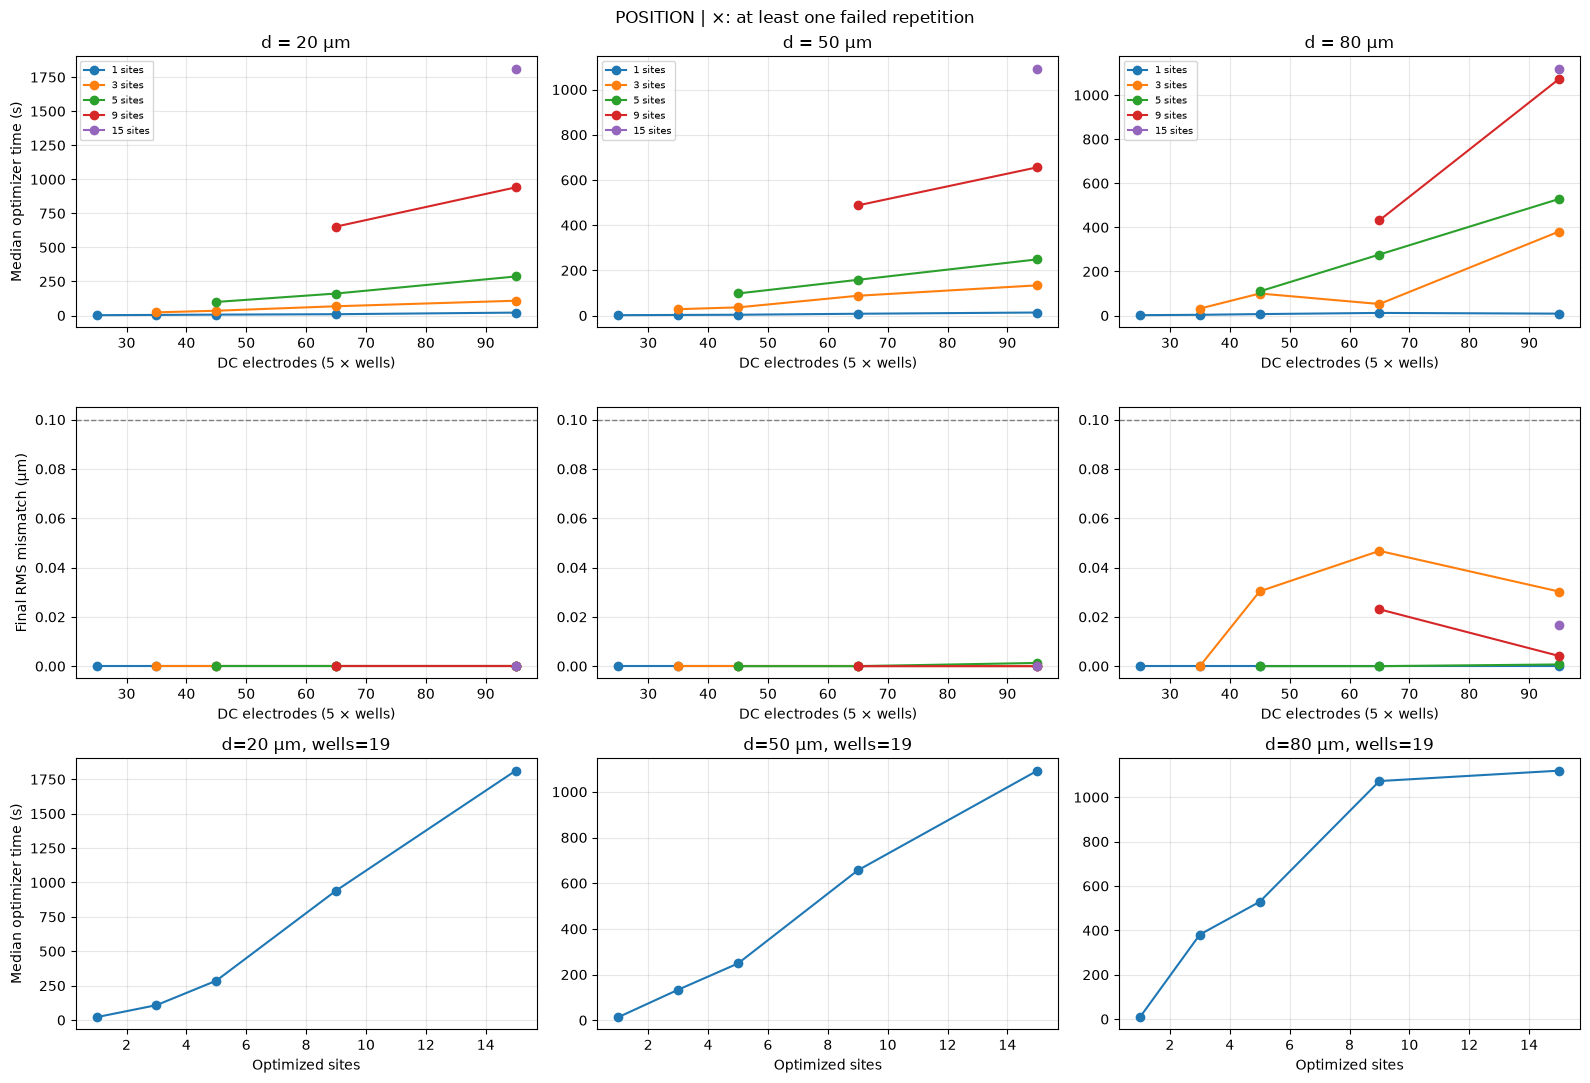

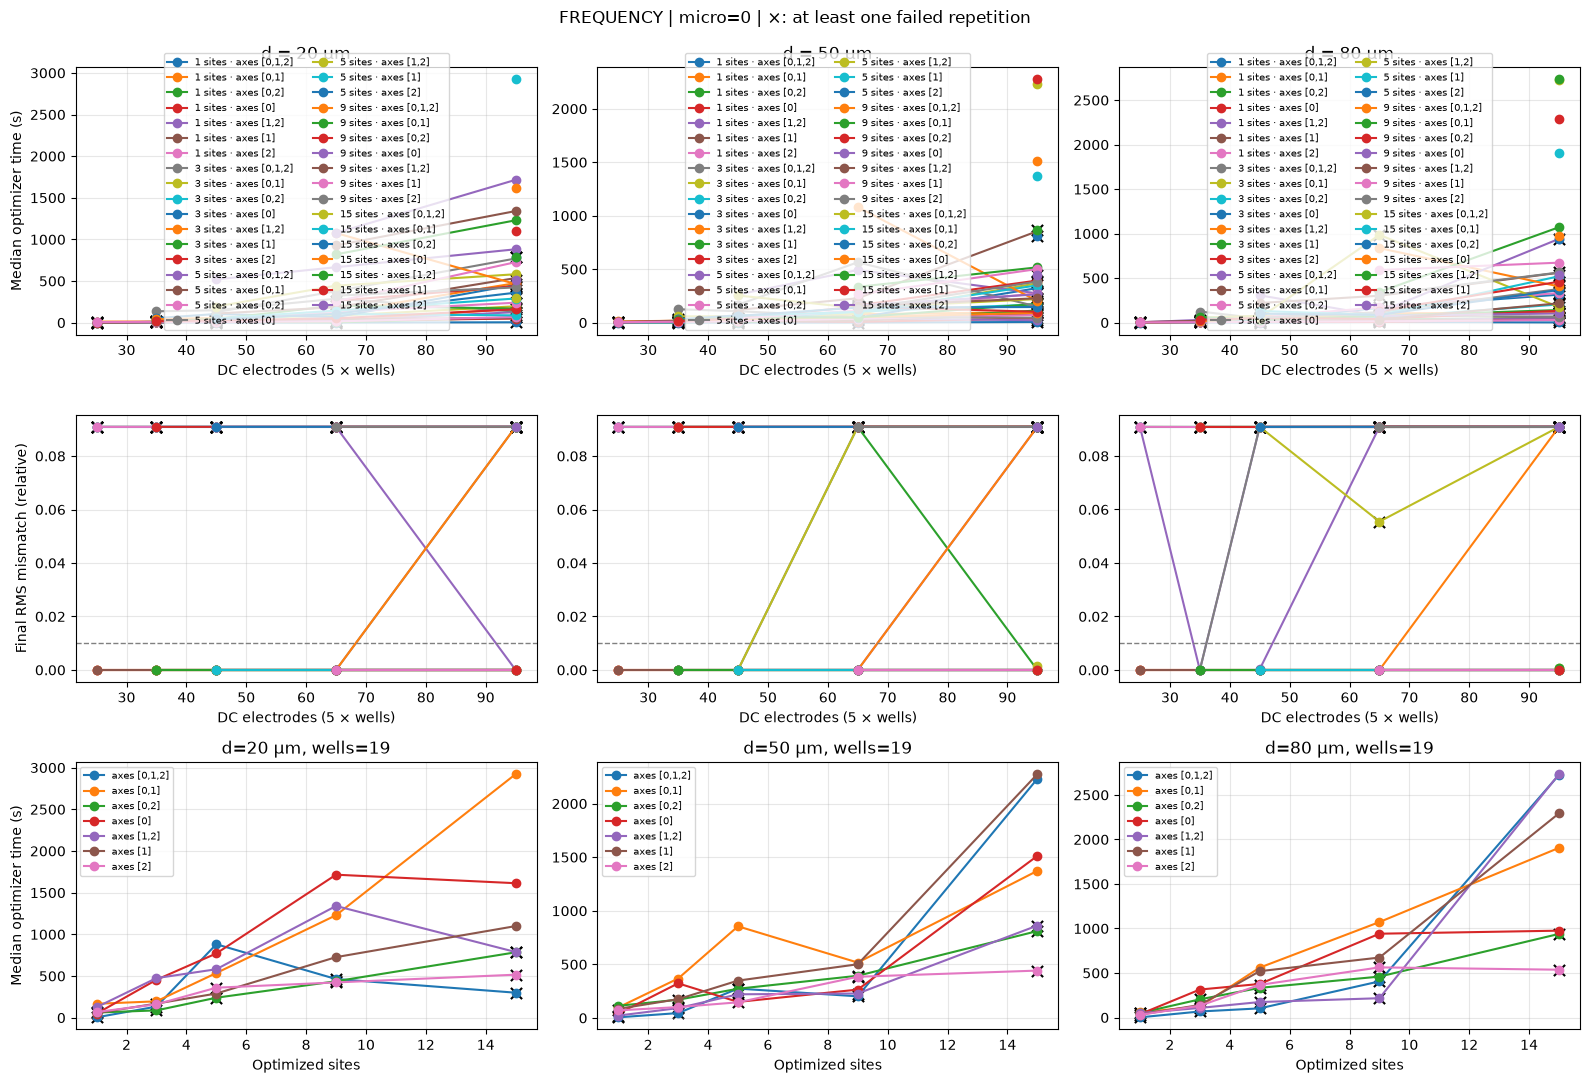

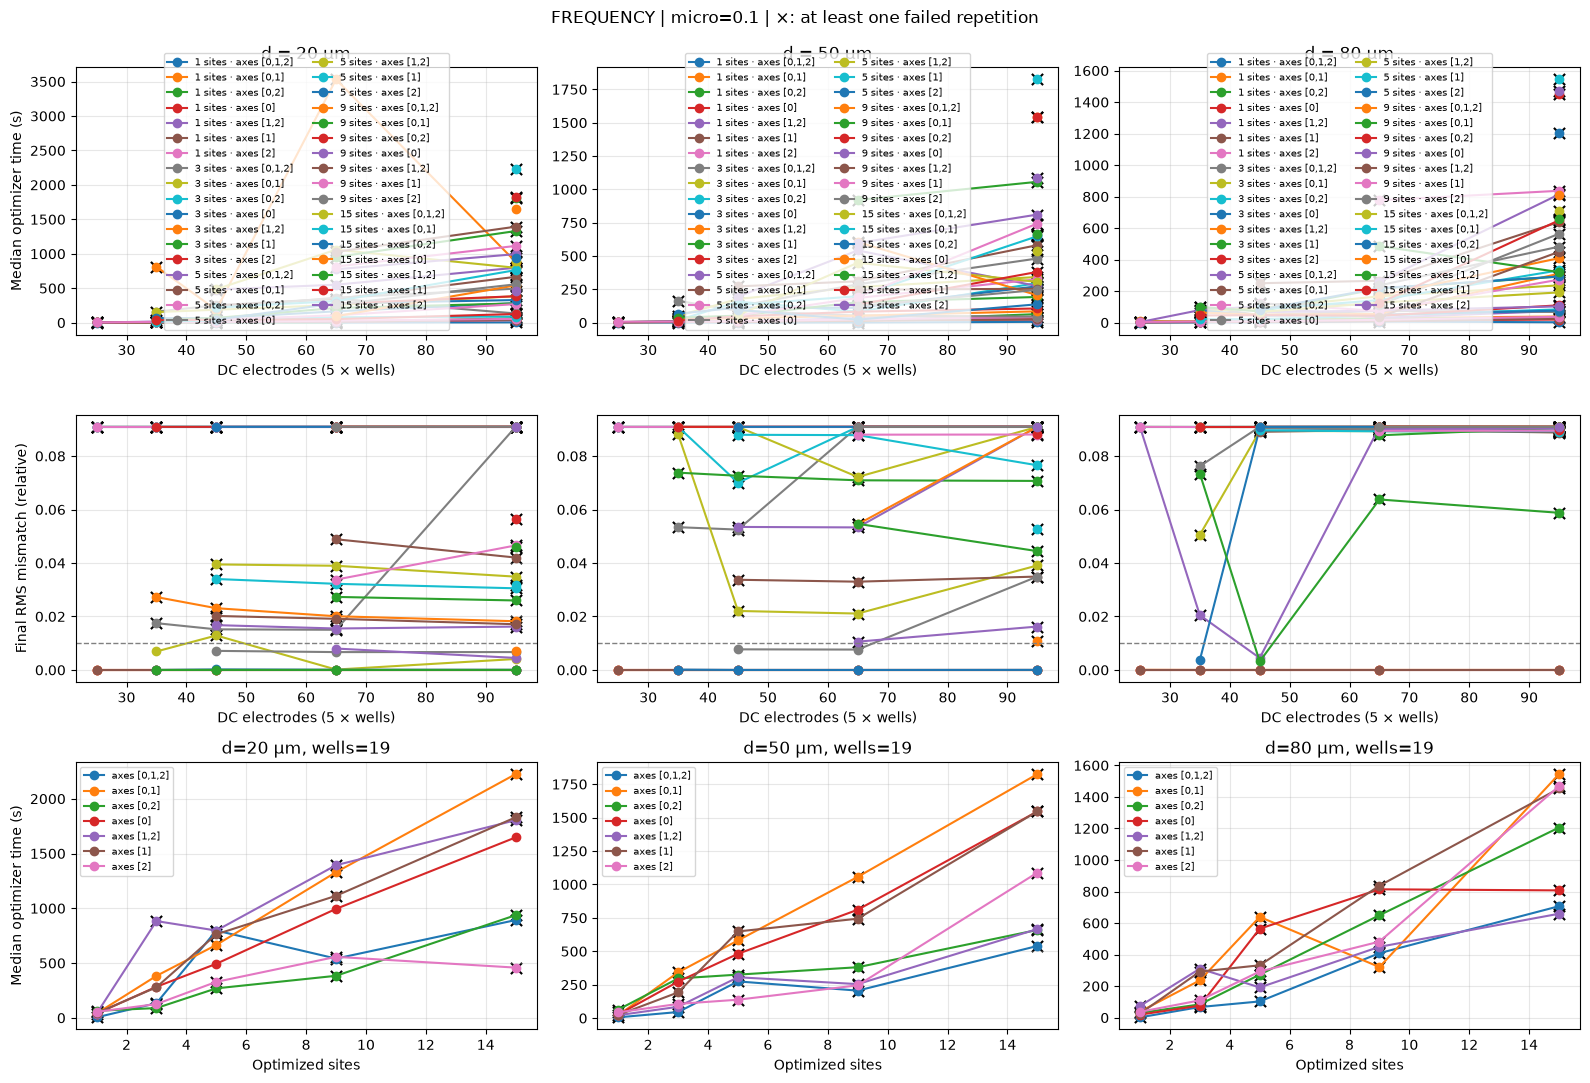

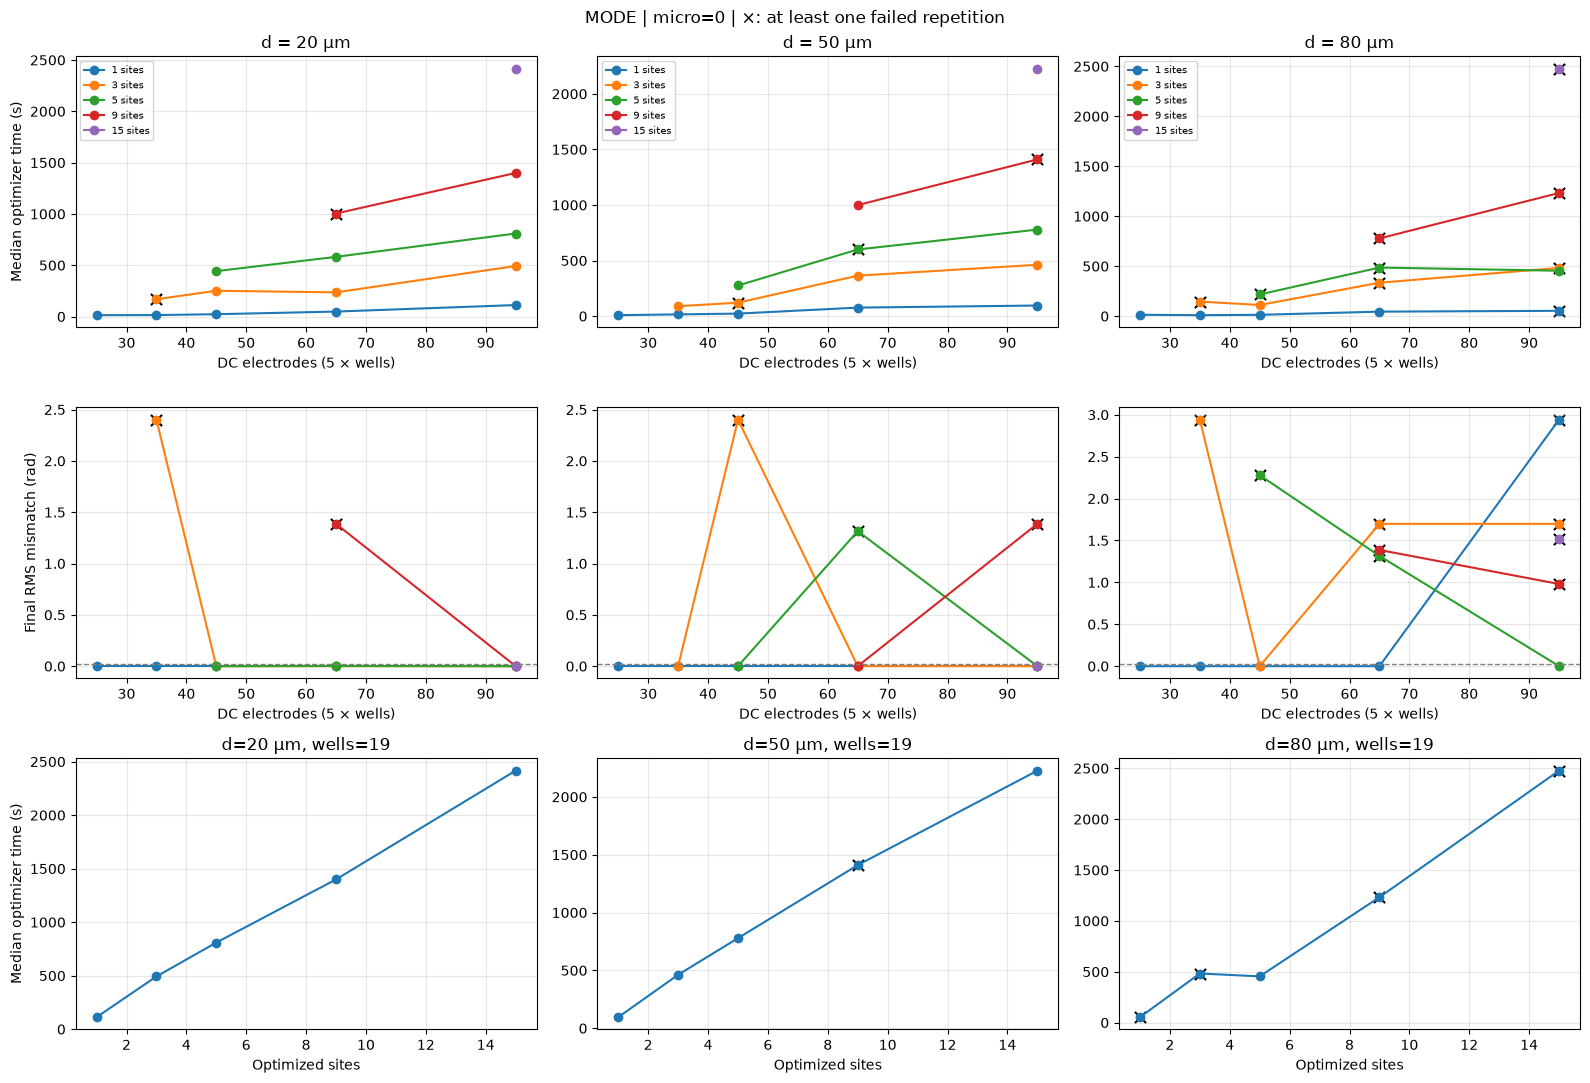

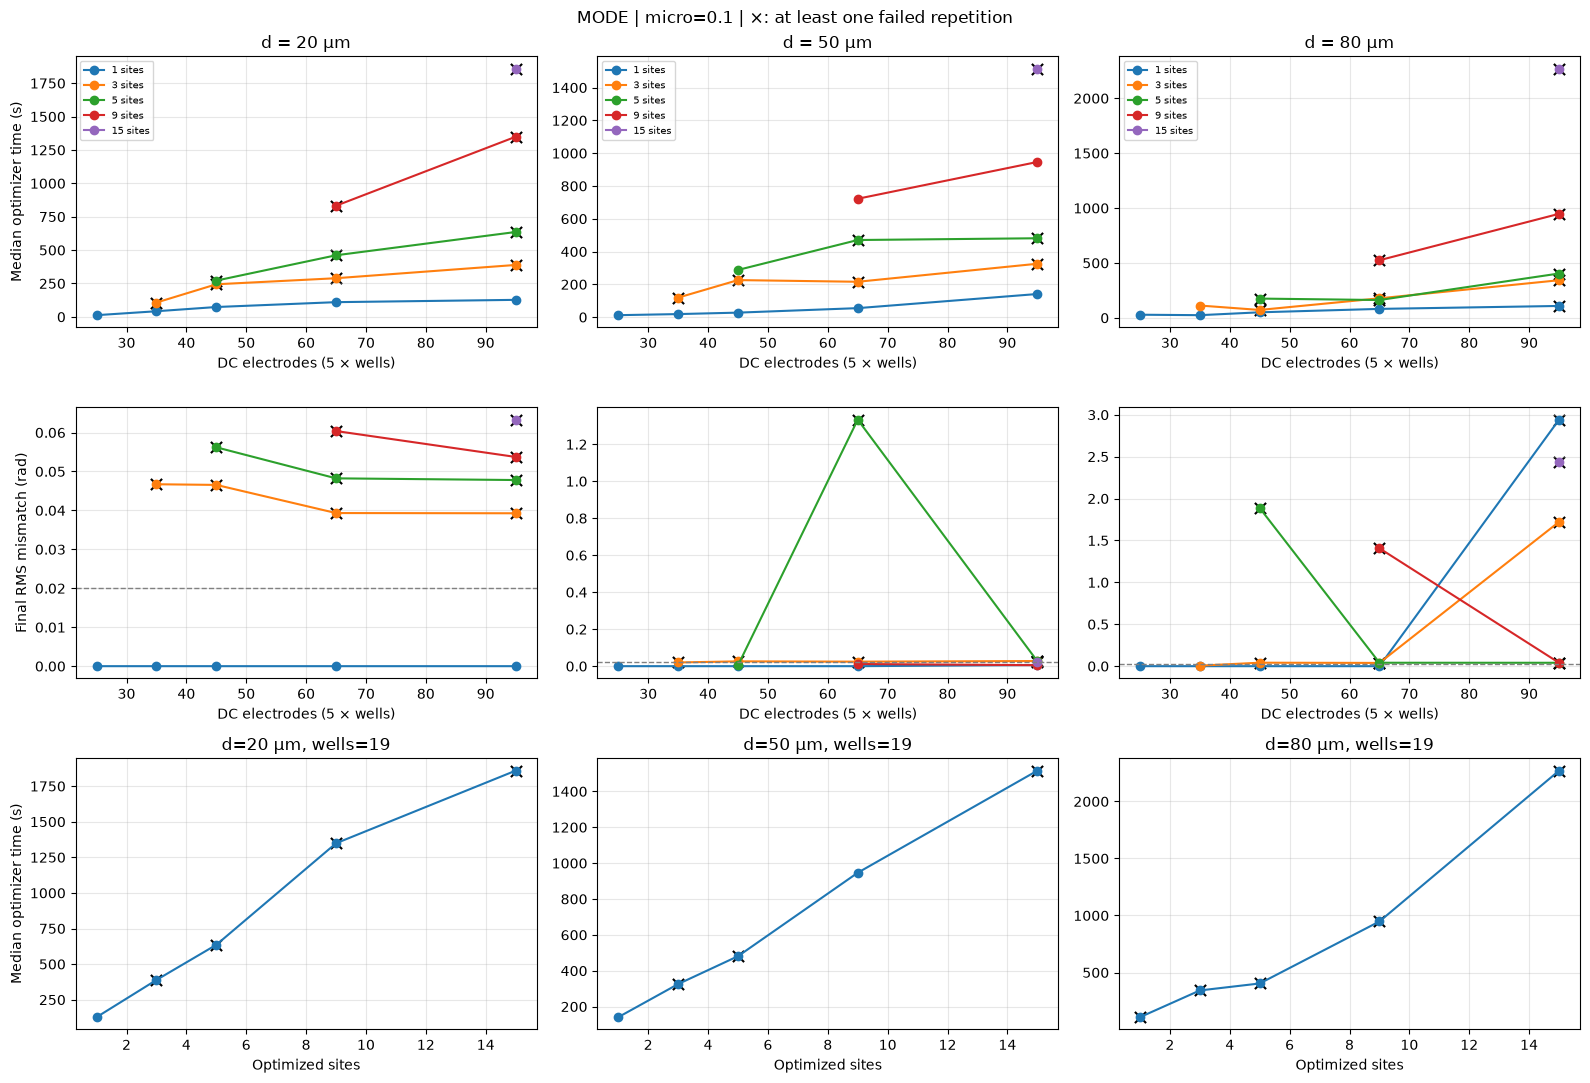

In [6]:
def plot_task(runs, task, micro=0):
    data = runs[(runs['task'] == task) & runs['solver_time_s'].notna()].copy()
    if task != 'position':
        data = data[np.isclose(data['micro'], micro)]
    if data.empty:
        print('No results for', task, 'micro=', micro)
        return
    keys = ['d_um', 'n_points', 'n_squares', 'n_dc', 'axes']
    summary = (data.groupby(keys, as_index=False)
               .agg(solver_time_s=('solver_time_s','median'),
                    error_rms=('error_rms','median'),
                    success_rate=('success','mean')))

    fig, panel = plt.subplots(3, 3, figsize=(16, 11), squeeze=False)
    for col, d in enumerate((20, 50, 80)):
        cur = summary[summary.d_um == d]
        for (n, axes), group in cur.groupby(['n_points', 'axes']):
            group = group.sort_values('n_dc')
            label = f'{n} sites' + (f' · axes {axes}' if task == 'frequency' else '')
            panel[0,col].plot(group.n_dc, group.solver_time_s, 'o-', label=label)
            panel[1,col].plot(group.n_dc, group.error_rms, 'o-', label=label)
            bad = group[group.success_rate < 1]
            panel[0,col].scatter(bad.n_dc, bad.solver_time_s, marker='x', color='black', s=65)
            panel[1,col].scatter(bad.n_dc, bad.error_rms, marker='x', color='black', s=65)
        if not cur.empty:
            subset = cur[cur.n_squares == cur.n_squares.max()]
            for axes, group in subset.groupby('axes'):
                group = group.sort_values('n_points')
                label = f'axes {axes}' if task == 'frequency' else task
                panel[2,col].plot(group.n_points, group.solver_time_s, 'o-', label=label)
                bad = group[group.success_rate < 1]
                panel[2,col].scatter(bad.n_points, bad.solver_time_s,
                                     marker='x', color='black', s=65)
            panel[2,col].set_title(f'd={d} µm, wells={int(cur.n_squares.max())}')
        panel[0,col].set_title(f'd = {d} µm')
        for row in range(3):
            panel[row,col].grid(alpha=0.3)
        panel[0,col].set_xlabel('DC electrodes (5 × wells)')
        panel[1,col].set_xlabel('DC electrodes (5 × wells)')
        panel[2,col].set_xlabel('Optimized sites')
        if not cur.empty:
            panel[0,col].legend(fontsize=7, ncol=2 if task=='frequency' else 1)
            if task == 'frequency':
                panel[2,col].legend(fontsize=7)

    unit = {'position':'µm', 'frequency':'relative', 'mode':'rad'}[task]
    limit = {'position':POSITION_RMS_TOL_UM, 'frequency':FREQUENCY_RMS_REL_TOL,
             'mode':MODE_RMS_TOL_RAD}[task]
    for col in range(3):
        panel[1,col].axhline(limit, color='gray', linestyle='--', linewidth=1)
    panel[0,0].set_ylabel('Median optimizer time (s)')
    panel[1,0].set_ylabel(f'Final RMS mismatch ({unit})')
    panel[2,0].set_ylabel('Median optimizer time (s)')
    subtitle = '' if task == 'position' else f' | micro={micro}'
    fig.suptitle(task.upper() + subtitle + ' | ×: at least one failed repetition')
    fig.tight_layout()
    plt.show()


if not runs_df.empty:
    report = (runs_df[runs_df.task.isin(TASKS)]
              .groupby(['task', 'axes', 'micro', 'd_um'], as_index=False)
              .agg(cases=('success','size'), successes=('success','sum'),
                   median_time_s=('solver_time_s','median'),
                   median_error_rms=('error_rms','median')))
    display(report)
    for task in TASKS:
        if task == 'position':
            plot_task(runs_df, task)
        else:
            for micro in MICRO_VALUES:
                plot_task(runs_df, task, micro)


## 6. Summary

Results are summariesed on 4 figures. 3 figures for optimization wall times for each target by number of trapping sites and electrodes. Final is  RMS target mismatches for all tested workloads, normalized to each task's RMS tolerance. The frequency panel includes every axis combination and both micromotion weights. All three `d=20, 50, 80 µm` geometries are shown separately. Filled markers satisfy both the RMS and maximum-error acceptance criteria; open markers in runtime figures / crosses in verification indicate an unsuccessful target match.

To regenerate without rerunning the optimizers: set `RUN_BENCHMARK=False` and `LOAD_CSV` to the saved `*_runs.csv`, run the loading cell in Section 4, then run this cell. The four figures are exported as eps to `OUTPUT_DIR / 'publication_figures'`.


Run outcomes (all workloads):


,verified,attempts,success_fraction
task,,,
frequency,237,630,0.376190
mode,49,90,0.544444
position,45,45,1.000000


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


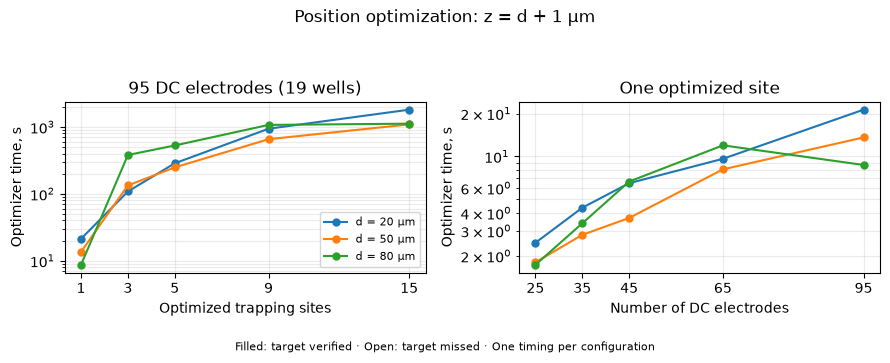

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


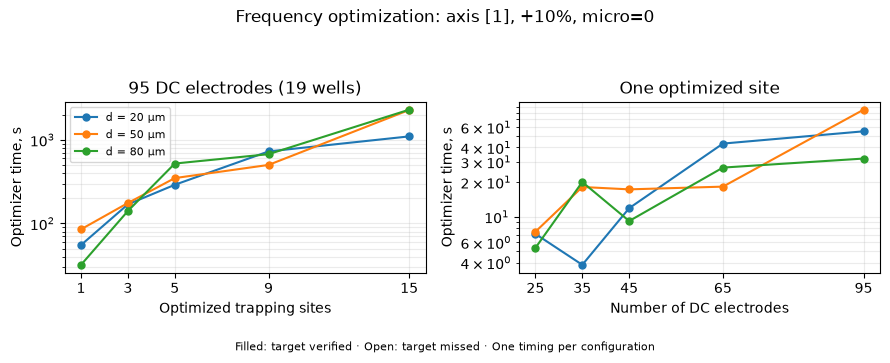

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


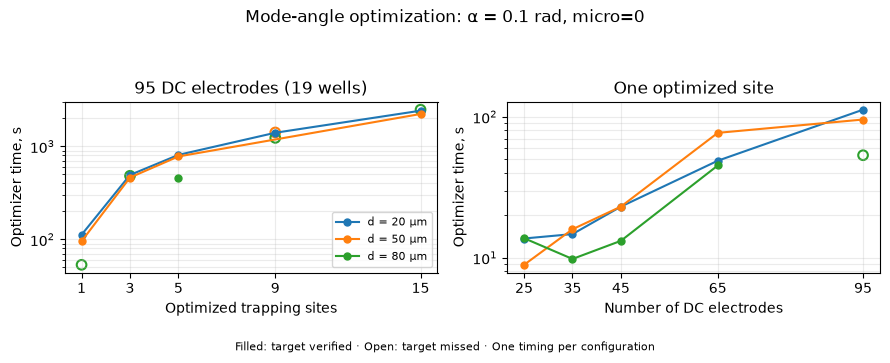

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


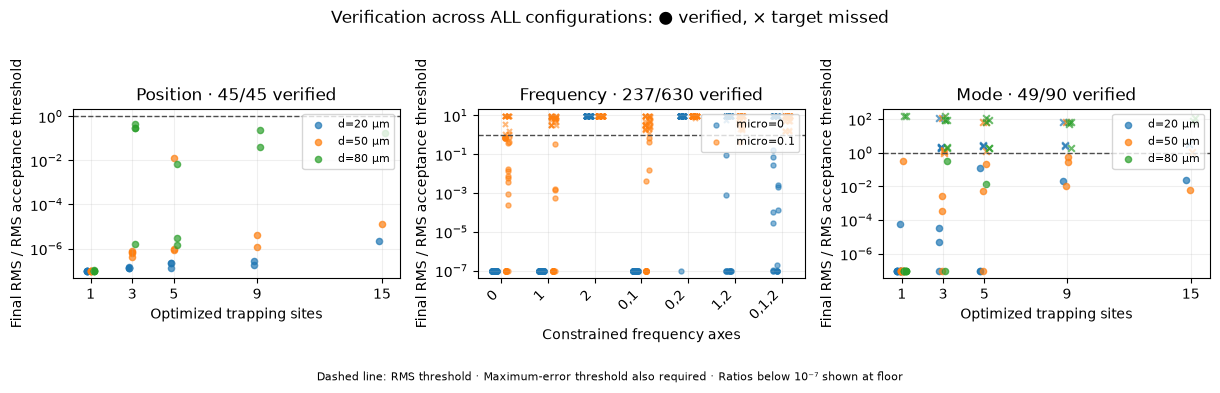

Figures saved in: c:\Users\User\Desktop\ARTEM\Sion\benchmark\supplementary\voltage_optimization\publication_figures


In [25]:
PAPER_CSV = None  # Optional: path to a previously saved *_runs.csv
if 'runs_df' in globals() and isinstance(runs_df, pd.DataFrame) and not runs_df.empty:
    paper = runs_df.copy()
elif PAPER_CSV is not None:
    paper = pd.read_csv(PAPER_CSV)
else:
    raise ValueError('Load runs_df first, or set PAPER_CSV to the saved *_runs.csv')

paper = paper[paper['task'].isin(['position', 'frequency', 'mode'])].copy()
paper['success'] = paper['success'].astype(str).str.lower().eq('true')
paper['solver_time_s'] = pd.to_numeric(paper['solver_time_s'], errors='coerce')
paper['error_rms'] = pd.to_numeric(paper['error_rms'], errors='coerce')
paper['micro'] = pd.to_numeric(paper['micro'], errors='coerce')
fig_dir = Path(OUTPUT_DIR if 'OUTPUT_DIR' in globals() else '.') / 'publication_figures'
fig_dir.mkdir(parents=True, exist_ok=True)
colors = {20: 'C0', 50: 'C1', 80: 'C2'}
limits = {'position': 0.1, 'frequency': 0.01, 'mode': 0.02}

def save_figure(fig, name):
    fig.savefig(fig_dir / f'{name}.png', dpi=300, bbox_inches='tight')
    fig.savefig(fig_dir / f'{name}.eps', bbox_inches='tight')


def scaling_figure(task):
    subset = paper[(paper['task'] == task) & paper['solver_time_s'].notna()].copy()
    if task == 'frequency':
        subset = subset[(subset['axes'] == '[1]') & np.isclose(subset['micro'], 0)]
    elif task == 'mode':
        subset = subset[np.isclose(subset['micro'], 0)]

    fig, axs = plt.subplots(1, 2, figsize=(9, 3.5))
    panels = [(subset[subset['n_squares'] == 19], 'n_points', 'Optimized trapping sites',
               '95 DC electrodes (19 wells)'),
              (subset[subset['n_points'] == 1], 'n_dc', 'Number of DC electrodes',
               'One optimized site')]
    for ax, (selection, x, xlabel, title) in zip(axs, panels):
        for d, color in colors.items():
            group = selection[selection['d_um'] == d].sort_values(x)
            valid = group[group['success']]
            failed = group[~group['success']]
            ax.plot(valid[x], valid['solver_time_s'], 'o-', color=color,
                    linewidth=1.5, markersize=5, label=f'd = {d} µm')
            ax.scatter(failed[x], failed['solver_time_s'], s=48, marker='o',
                       facecolors='none', edgecolors=color, linewidths=1.5)
        ax.set(xlabel=xlabel, ylabel='Optimizer time, s', title=title)
        ax.set_yscale('log')
        ax.grid(alpha=0.25, which='both')
        ax.set_xticks(sorted(selection[x].dropna().unique()))
    names = {'position': 'Position optimization: z = d + 1 µm',
             'frequency': 'Frequency optimization: axis [1], +10%, micro=0',
             'mode': 'Mode-angle optimization: α = 0.1 rad, micro=0'}
    fig.suptitle(names[task], fontsize=12)
    axs[0].legend(fontsize=8)
    fig.text(0.5, 0.005, 'Filled: target verified · Open: target missed · One timing per configuration',
             ha='center', fontsize=8)
    fig.tight_layout(rect=(0, .06, 1, .91))
    save_figure(fig, f'scaling_{task}')
    return fig


def verification_figure():
    fig, axs = plt.subplots(1, 3, figsize=(12.3, 3.8))
    floor = 1e-7  # only for display on a logarithmic axis
    for ax, task in zip(axs, ['position', 'frequency', 'mode']):
        part = paper[(paper['task'] == task) & paper['error_rms'].notna()].copy()
        part['ratio'] = np.maximum(part['error_rms'] / limits[task], floor)
        if task == 'frequency':
            choices = ['[0]', '[1]', '[2]', '[0,1]', '[0,2]', '[1,2]', '[0,1,2]']
            for micro, color in [(0, 'C0'), (0.1, 'C1')]:
                group = part[np.isclose(part['micro'], micro)]
                x = np.array([choices.index(a) for a in group['axes']], float)
                # Deterministic offset: separates the two workloads and geometries.
                x += (-0.13 if micro == 0 else 0.13)
                x += ((group['n_points'].to_numpy() % 5) - 2) * 0.025
                good = group['success'].to_numpy()
                ax.scatter(x[good], group['ratio'].to_numpy()[good], s=13,
                           color=color, alpha=0.55, label=f'micro={micro}')
                ax.scatter(x[~good], group['ratio'].to_numpy()[~good], s=13,
                           color=color, alpha=0.55, marker='x')
            ax.set_xticks(range(7), [s.strip('[]') for s in choices], rotation=45, ha='right')
            ax.set_xlabel('Constrained frequency axes')
            ax.legend(fontsize=8, loc='upper right')
        else:
            for d, color in colors.items():
                group = part[part['d_um'] == d]
                x = group['n_points'].to_numpy(dtype=float) + (d - 50) / 200
                if task == 'mode':
                    x += (group['micro'].to_numpy() - 0.05) * 1.2
                good = group['success'].to_numpy()
                ax.scatter(x[good], group['ratio'].to_numpy()[good], s=20,
                           color=color, alpha=0.7, label=f'd={d} µm')
                ax.scatter(x[~good], group['ratio'].to_numpy()[~good], s=23,
                           color=color, alpha=0.7, marker='x')
            ax.set_xticks(sorted(part['n_points'].unique()))
            ax.set_xlabel('Optimized trapping sites')
            ax.legend(fontsize=8, loc='upper right')
        ax.axhline(1, color='0.3', linestyle='--', linewidth=1)
        ax.set_yscale('log')
        ax.set_ylabel('Final RMS / RMS acceptance threshold')
        ax.grid(alpha=0.2, which='both')
        ax.set_title(f'{task.capitalize()} · {int(part.success.sum())}/{len(part)} verified')
    fig.suptitle('Verification across ALL configurations: ● verified, × target missed', fontsize=12)
    fig.text(0.5, 0.005, 'Dashed line: RMS threshold · Maximum-error threshold also required · Ratios below 10⁻⁷ shown at floor',
             ha='center', fontsize=8)
    fig.tight_layout(rect=(0, .065, 1, .90))
    save_figure(fig, 'verification_all')
    return fig

# One concise table; retain the detailed per-configuration report above.
print('Run outcomes (all workloads):')
display(paper.groupby('task')['success'].agg(['sum', 'count', 'mean']).rename(
    columns={'sum': 'verified', 'count': 'attempts', 'mean': 'success_fraction'}))
for task in ('position', 'frequency', 'mode'):
    scaling_figure(task)
    plt.show()
verification_figure()
plt.show()
print('Figures saved in:', fig_dir)


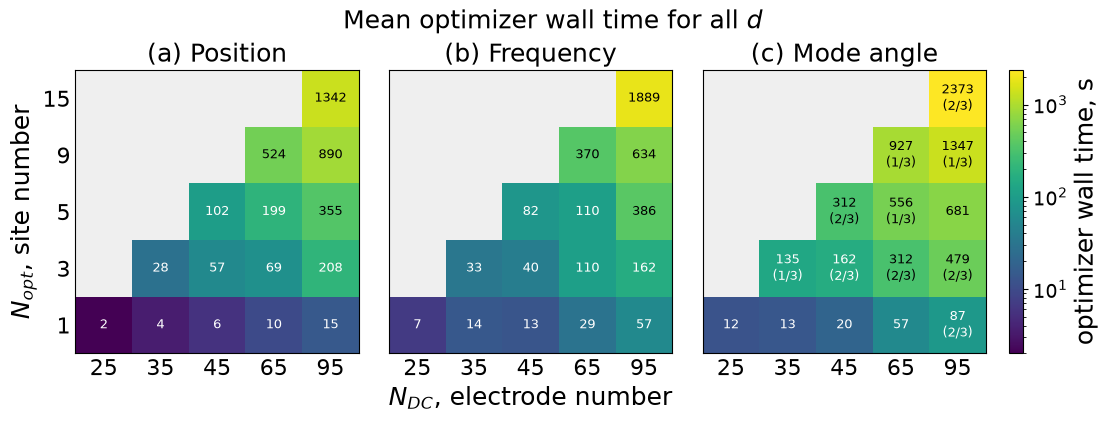

In [26]:
# Publication summary: wall-time heatmaps for the three representative workloads.
from matplotlib.colors import LogNorm

heatmap_data = paper.copy() 
heatmap_data = heatmap_data[
    (heatmap_data['task'] == 'position') |
    ((heatmap_data['task'] == 'frequency') & (heatmap_data['axes'] == '[1]') &
     np.isclose(heatmap_data['micro'], 0)) |
    ((heatmap_data['task'] == 'mode') & np.isclose(heatmap_data['micro'], 0))
].copy()
heatmap_data = heatmap_data[heatmap_data['solver_time_s'].gt(0) &
                            np.isfinite(heatmap_data['solver_time_s'])]

# Mean over the three height presets (and repetitions, if available).
# Include failed attempts in measured wall time, but identify them explicitly.
heatmap_summary = heatmap_data.groupby(['task', 'n_points', 'n_dc']).agg(
    wall_time=('solver_time_s', 'mean'),
    verified=('success', 'sum'),
    attempts=('success', 'size')
).reset_index()

sites = sorted(heatmap_summary['n_points'].unique())
electrodes = sorted(heatmap_summary['n_dc'].unique())
norm = LogNorm(vmin=heatmap_summary['wall_time'].min(),
               vmax=heatmap_summary['wall_time'].max())
cmap = plt.get_cmap('viridis').copy()
cmap.set_bad('0.94')  # Untested / unavailable configurations.

fig, axs = plt.subplots(1, 3, figsize=(11, 4.1), sharey=True,
                        constrained_layout=True)
for ax, task, title in zip(axs, ['position', 'frequency', 'mode'],
                           ['(a) Position', '(b) Frequency', '(c) Mode angle']):
    data = heatmap_summary[heatmap_summary['task'] == task]
    times = data.pivot(index='n_points', columns='n_dc', values='wall_time')
    times = times.reindex(index=sites, columns=electrodes)
    im = ax.imshow(times.to_numpy(), origin='lower', aspect='equal',
                   cmap=cmap, norm=norm, interpolation='none')

    for row in data.itertuples(index=False):
        x = electrodes.index(row.n_dc)
        y = sites.index(row.n_points)
        label = f'{int(np.round(row.wall_time))}'
        if row.verified < row.attempts:
            label += f'\n({row.verified}/{row.attempts})'
        r, g, b, _ = cmap(norm(row.wall_time))
        text_color = 'black' if 0.299*r + 0.587*g + 0.114*b > 0.55 else 'white'
        ax.text(x, y, label, ha='center', va='center', fontsize=9, color=text_color)

    ax.set_xticks(range(len(electrodes)), electrodes, fontsize=16)
    ax.set_yticks(range(len(sites)), sites, fontsize=16)
    # ax.set_xlabel(r'$N_{DC}$, electrode number', fontsize=18)
    ax.set_title(title, fontsize=18)
    ax.tick_params(length=0)

axs[0].set_ylabel(r'$N_{opt}$, site number', fontsize=18)
axs[1].set_xlabel(r'$N_{DC}$, electrode number', fontsize=18)
cbar = fig.colorbar(im, ax=axs, shrink=1, pad=0.025)
cbar.set_label('optimizer wall time, s', fontsize=18)
cbar.set_ticks([10, 100, 1000])
cbar.set_ticklabels(['$10^1$','$10^2$','$10^3$' ], fontsize=14)
fig.suptitle('Mean optimizer wall time for all $d$',
             fontsize=18)
save_figure(fig, 'scaling_heatmaps')
plt.show()